# Iris Flower Classification

CodeAlpha Task 1. Predict species from four flower measurements, excluding the record identifier. This notebook runs the same reproducible, group-aware pipeline as the CLI. See `README.md` for provenance, model grids, and validation details.


## Evaluation plan

Seed 42; keep identical measurement vectors together. Reserve the first fold of a five-fold stratified group split as the held-out test set. Compare a dummy baseline, logistic regression, KNN, and RBF SVM with five-fold group-aware CV on training data only. Fit standardization inside each model pipeline. Select by training CV macro F1 and evaluate the chosen estimator once on the held-out partition.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display
import analysis

metrics = analysis.main([])
output = Path(analysis.__file__).resolve().parent / "outputs"


Selected: logistic_regression; test accuracy=1.0000; macro F1=1.0000
Outputs: /workspace/codealpha-projects/CodeAlpha_IrisFlowerClassification/outputs


In [2]:
display(pd.DataFrame(metrics["model_selection"]))
display(pd.DataFrame(metrics["test"]["classification_report"]).T)
print("Held-out split:", metrics["split"])


,model,mean_cv_macro_f1,std_cv_macro_f1,mean_cv_accuracy,parameters
0,logistic_regression,0.966601,0.031198,0.966667,{'classifier__C': 10.0}
1,knn,0.958235,0.026352,0.958333,{'classifier__n_neighbors': 3}
2,rbf_svm,0.958235,0.026352,0.958333,{'classifier__C': 1.0}
3,dummy_most_frequent,0.166667,0.000000,0.333333,{}


,precision,recall,f1-score,support
Iris-setosa,1.0,1.0,1.0,10.0
Iris-versicolor,1.0,1.0,1.0,10.0
Iris-virginica,1.0,1.0,1.0,10.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,30.0
weighted avg,1.0,1.0,1.0,30.0


Held-out split: {'method': 'First fold of StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)', 'train_rows': 120, 'test_rows': 30, 'train_unique_groups': 119, 'test_unique_groups': 28, 'overlapping_groups': 0, 'train_class_counts': {'Iris-setosa': 40, 'Iris-versicolor': 40, 'Iris-virginica': 40}, 'test_class_counts': {'Iris-setosa': 10, 'Iris-versicolor': 10, 'Iris-virginica': 10}}


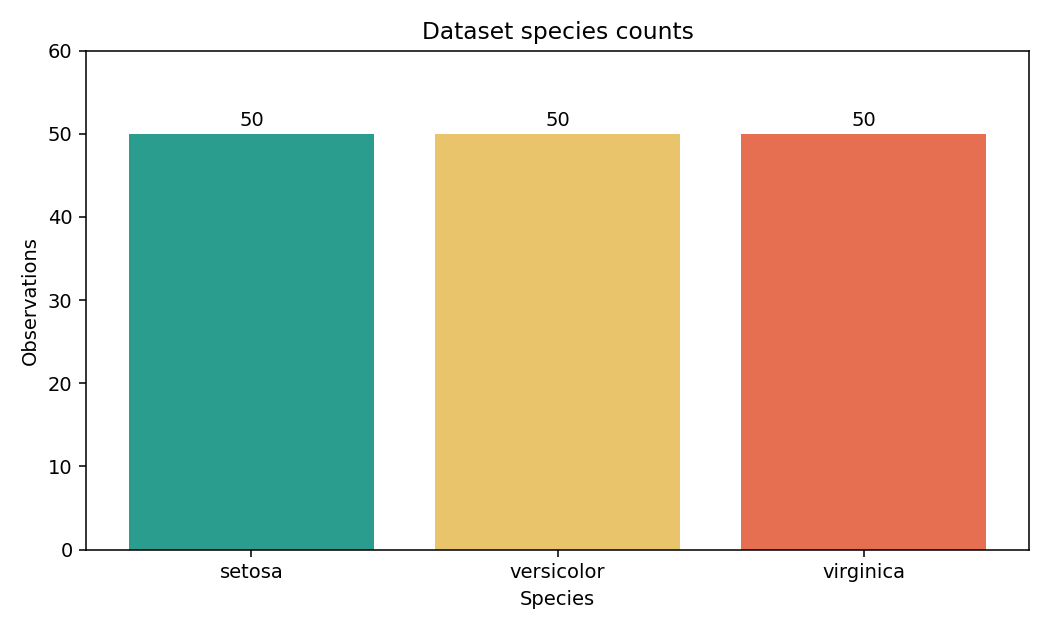

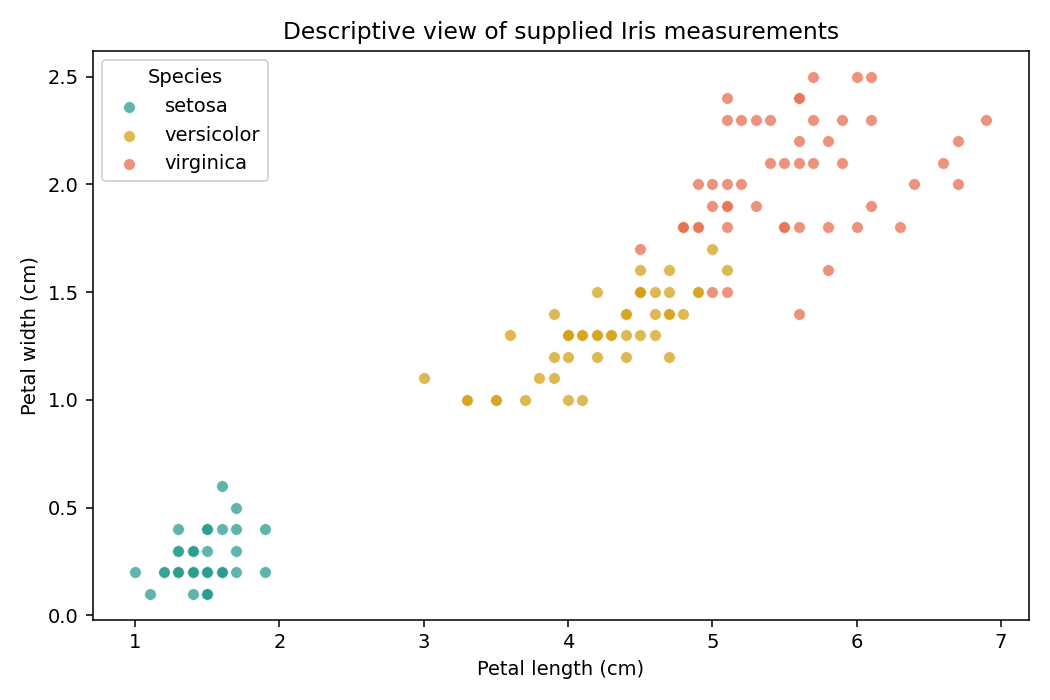

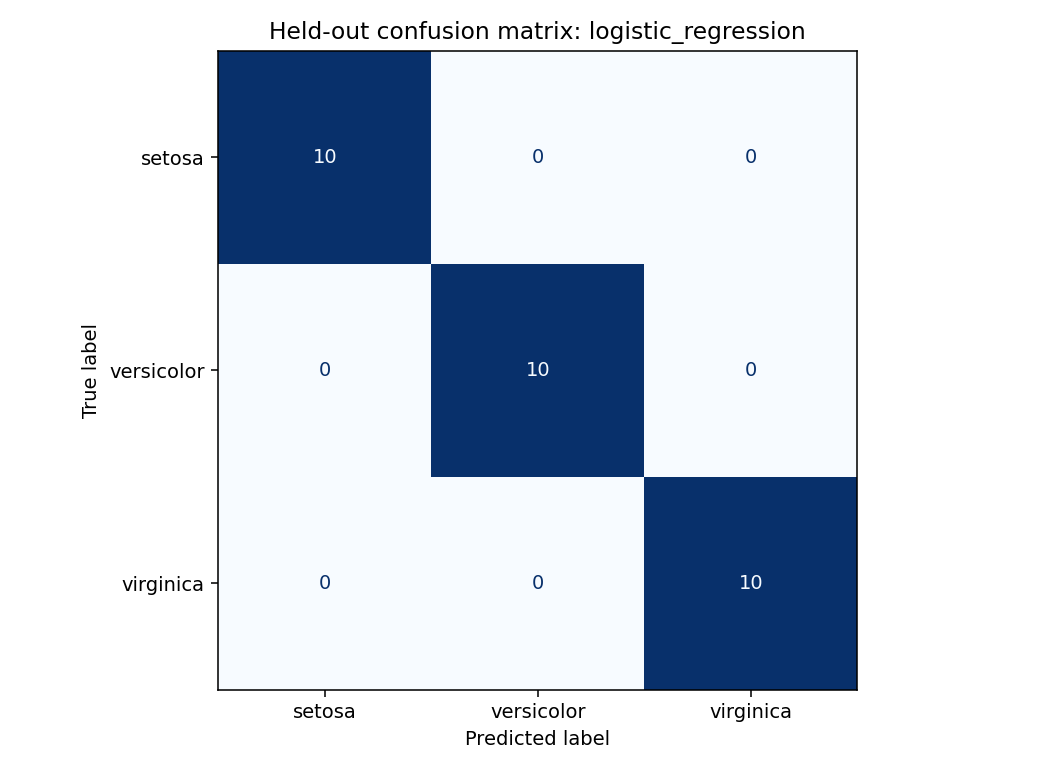

In [3]:
display(Image(filename=str(output / "class_distribution.png")))
display(Image(filename=str(output / "petal_measurements.png")))
display(Image(filename=str(output / "confusion_matrix.png")))


In [4]:
display(Markdown((output / "summary.md").read_text(encoding="utf-8")))


# Iris flower classification: results and design report

## Objective
Classify Iris setosa, versicolor, and virginica using four flower measurements in centimetres. This is an educational supervised learning exercise.

## Data and provenance
The user supplied `data/Iris.csv`: 150 observations, 50 per species. There are no missing values or duplicate complete rows; Id distinguishes records. There are 3 repeated measurement-and-label rows and 147 unique measurement groups. No measurement group has conflicting labels. The Id identifier is excluded from predictors.
The assignment links to https://www.kaggle.com/datasets/saurabh00007/iriscsv. The actual input is the user-uploaded CSV, not a fresh download from that page. Collection details, independence of observations, and redistribution license were not independently established. The file is retained as supplied; no license is asserted.

## Method and evaluation design
Seed 42; the first fold from a five-fold shuffled StratifiedGroupKFold defines the held-out set. This produces 120 training and 30 test rows. Identical measurement groups stay together. Stratification is approximate under group constraints.
Model families and grids were fixed in code before evaluation. A most-frequent baseline, standardized logistic regression, standardized k-nearest neighbours, and standardized radial-basis SVM are compared with five-fold group-aware cross-validation on training data only. Scaling is fit within each training fold. Mean macro F1 selects hyperparameters, with grid order breaking ties within a model. The model with highest best CV macro F1 is selected; mean CV accuracy and alphabetical model name break model-level ties. The selected estimator is refit on the training partition, then the held-out set is evaluated once. The baseline test result is reported for context; no model is chosen using test performance.

## Results
| Candidate | Best mean CV macro F1 | CV standard deviation | Best mean CV accuracy |
|---|---:|---:|---:|
| logistic_regression | 0.9666 | 0.0312 | 0.9667 |
| knn | 0.9582 | 0.0264 | 0.9583 |
| rbf_svm | 0.9582 | 0.0264 | 0.9583 |
| dummy_most_frequent | 0.1667 | 0.0000 | 0.3333 |

Selected **logistic_regression**, parameters `{"classifier__C": 10.0}`. Held-out accuracy **1.0000** and macro F1 **1.0000**, with 0 misclassified observations out of 30. Baseline held-out accuracy is 0.3333 and macro F1 is 0.1667.

| Species | Test support | Precision | Recall | F1 |
|---|---:|---:|---:|---:|
| Iris-setosa | 10 | 1.0000 | 1.0000 | 1.0000 |
| Iris-versicolor | 10 | 1.0000 | 1.0000 | 1.0000 |
| Iris-virginica | 10 | 1.0000 | 1.0000 | 1.0000 |

The descriptive petal plot shows strong setosa separation and greater overlap between versicolor and virginica. The confusion matrix and `test_predictions.csv` identify the observed held-out errors. These plots summarize the supplied data and held-out predictions; they do not establish causal feature effects.

## Limitations
A small, balanced educational dataset and one held-out split provide a noisy estimate of performance. A high score is not evidence of production readiness or performance on new locations, instruments, or flower populations. Hyperparameter selection adds training-set selection uncertainty. Grouping identical measurement vectors reduces direct duplicate leakage but cannot identify unrecorded relationships between flowers. Species labels and measurements have not been externally verified. No unseen external dataset or deployment testing was performed.

## Reproducibility
Run `python analysis.py`, then `python -m unittest discover -s tests -v`. The notebook calls the same pipeline. `metrics.json` records versions, split sizes, class counts, parameters, and complete test metrics; `split_assignments.csv` records every row's split and feature group; `cv_results.csv` records all tried configurations. The selected estimator is evaluated after fitting on training data only; it is not refit on the held-out observations.


## Interpretation and limits

The held-out sample has only 30 flowers. High performance on this small educational dataset does not imply production readiness. Feature grouping prevents direct duplicate overlap, but unrecorded relationships between observations remain unknown. Data collection details and redistribution license have not been independently established. No external dataset was used.
